# P-1-1: geometry, motion, and localized identity warnings

Existing manual labels evaluate all seven fixed geometry arms. No appearance
classifier or new pose inference was used; no new annotation was created. Coverage starts
at 300 s on the native acquisition clock. This is a retrospective comparison
within one trio; warning thresholds are not independently validated elsewhere.

The original row-repaired extraction stays unchanged. `r1` tested position
and bidirectional bridges. `r2` stopped at an evaluation-mask invariant;
`r3` corrects that comparison adapter and is the valid follow-up.

In [1]:
import json
import sys
import tomllib
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import medaka3d
from medaka3d import load_paths

matplotlib.use("module://matplotlib_inline.backend_inline")
repo = Path(medaka3d.__file__).resolve().parents[2]
assert Path(sys.prefix).resolve() == (repo / ".venv").resolve()
analysis = repo / "analyses/20261031_p11_identity_evaluation"
policy = tomllib.loads((analysis / "config_geometry_risk_v3.toml").read_text())
source_cfg = tomllib.loads((analysis / policy["source_config"]).read_text())
root = load_paths().raw_data_dir.parent / source_cfg["output"]["relative_to_data_parent"]
run = root / policy["run_id"]
first = root / policy["first_experiment"]
assert json.loads((run / "status.json").read_text())["status"] == "complete"
validation = json.loads((run / "audit_v1/validation.json").read_text())
warnings = pd.read_csv(run / "warning_summary.csv")
scores = pd.read_csv(run / "correction_summary.csv")
first_scores = pd.read_csv(first / "correction_summary.csv")
core = warnings[warnings.rule.eq("identity_core")].copy()
core["contained_percent"] = 100 * core.groups_contained / core.group_count
counts = pd.read_csv(run / "audit_v1/c30_connection_summary.csv")
figures = run / "report_v1/figures"
figures.mkdir(exist_ok=True)
shown = 0.767
print("Input:", source_cfg["run_id"], "| Comparison:", run.name)
print("Checksummed comparison artifacts:", validation["manifest_artifacts_verified"])

Input: id_row_mapping_20261102_r1 | Comparison: geometry_motion_risk_20261104_r3
Checksummed comparison artifacts: 106


## Does motion improve the automatic connections?

The permissive C30 variant removes only the 2.5 mm median prerequisite for
velocity decisions; the other v4 rules and C34 remain fixed. A lower total
error in one arm does not compensate for new incorrect connections elsewhere.
Fish-seconds count each affected fish separately. Adjacent and gap endpoint
changes are reported separately and are not counts of physical swap events.

In [2]:
full = scores[scores.block.eq("all") & ~scores.method.eq("reference_endpoint_oracle")]
comparison = full.pivot(index="lambda_mm", columns="method", values="wrong_seconds")
display(comparison.round(3))
display(counts.groupby("lambda_mm")[["corrected_edges", "newly_wrong_edges",
                                   "unchanged_wrong_edges"]].sum())
display(first_scores[first_scores.block.eq("all") & first_scores.lambda_mm.eq(shown)]
        [["method", "wrong_seconds", "corrected_seconds", "newly_wrong_seconds"]].round(3))

method,baseline,c30_permissive_velocity
lambda_mm,,
0.000,3271.779,3038.189
0.100,3883.358,3349.457
0.250,2678.673,1611.095
0.500,2935.217,3018.590
0.767,848.417,3612.210
2.000,4285.441,3579.723
8.000,4133.675,3692.955


,corrected_edges,newly_wrong_edges,unchanged_wrong_edges
lambda_mm,,,
0.000,4,0,404
0.100,4,0,123
0.250,4,0,107
0.500,4,0,91
0.767,6,0,89
2.000,5,1,82
8.000,4,0,74


,method,wrong_seconds,corrected_seconds,newly_wrong_seconds
80,baseline,848.417,0.000,0.000
84,position,2878.434,312.227,2342.244
88,bidirectional,848.417,0.000,0.000
92,consensus,848.417,0.000,0.000
96,reference_endpoint_oracle,15.839,834.723,2.145


## How much review can geometry concentrate?

The core warning is: fish separation <10 mm, an adjacent step >10 mm,
a non-identity nearest assignment, or a missing position. Pad by 0.05 s.
Ray-count churn and residual-only alerts remain observation-quality evidence,
outside this identity review queue. No reference labels enter detection.

A sustained reference transition has >=0.1 matched seconds and >=10 matches
on each side; overlapping uncertainty brackets form review groups. Full
containment is stricter than touching a warning. All observed changes,
including short ones, remain in separate tables. Do not equate groups with
independent crossings or guaranteed physical swaps.

,lambda_mm,interval_count,warning_seconds,warning_fraction,groups_contained,group_count,raw_contained,raw_changes,duration_p50_s,duration_p95_s,duration_p100_s
1,0.000,159,94.789,0.053,64,66,405,408,0.151,0.973,32.432
3,0.100,130,90.686,0.050,28,28,126,127,0.181,1.056,32.432
5,0.250,125,90.144,0.050,32,32,110,111,0.205,1.082,32.432
7,0.500,127,90.439,0.050,25,25,94,95,0.205,1.072,32.432
9,0.767,129,90.795,0.050,21,21,94,95,0.193,1.062,32.432
11,2.000,131,91.373,0.051,19,19,86,87,0.193,1.051,32.432
13,8.000,144,93.373,0.052,21,21,77,78,0.163,0.996,32.432


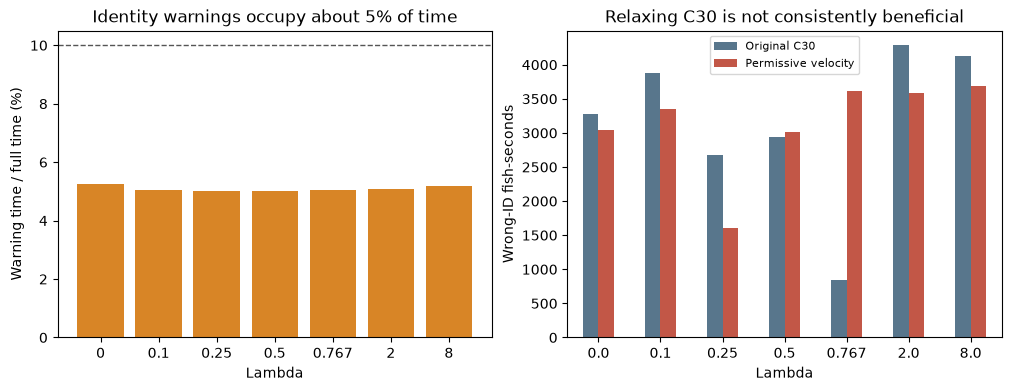

In [3]:
display(core[["lambda_mm", "interval_count", "warning_seconds", "warning_fraction",
              "groups_contained", "group_count", "raw_contained", "raw_changes",
              "duration_p50_s", "duration_p95_s", "duration_p100_s"]].round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
labels = [f"{v:g}" for v in core.lambda_mm]
axes[0].bar(labels, 100 * core.warning_fraction, color="#d88526")
axes[0].axhline(10, color="#555555", linestyle="--", linewidth=1)
axes[0].set(xlabel="Lambda", ylabel="Warning time / full time (%)",
            title="Identity warnings occupy about 5% of time")
comparison.plot.bar(ax=axes[1], color=["#58768c", "#c25747"], rot=0)
axes[1].set(xlabel="Lambda", ylabel="Wrong-ID fish-seconds",
            title="Relaxing C30 is not consistently beneficial")
axes[1].legend(["Original C30", "Permissive velocity"], fontsize=8)
fig.savefig(figures / "comparison.png", dpi=160)
plt.show()

## Where are the warning and lower-risk intervals?

Times below are recording seconds; native frame columns are retained in the
downloadable tables. Warning intervals are never cut merely to make clips
shorter. The two prolonged close encounters retain long ambiguity windows.

Unflagged intervals are lower-risk local continuity candidates. They can
inherit an earlier physical-ID error: a quiet track is not a verified name.
The lower-risk table includes reference coverage, observed label counts and
reference purity per slot so this distinction can be inspected directly.

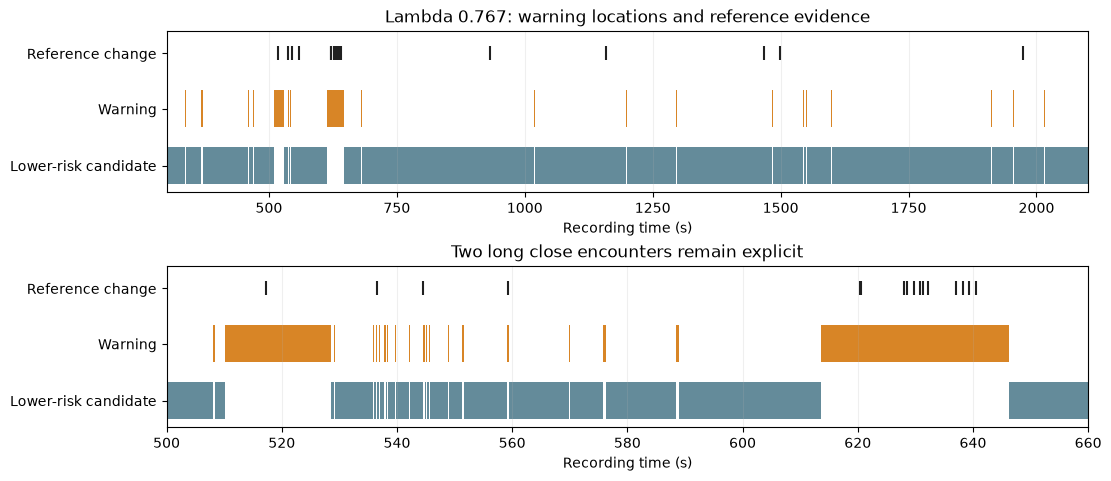

,interval_id,start_s,end_s,duration_s,reference_group_count,reasons
49,49,613.681,646.113,32.432,12,"missing_position,large_step,nonidentity_neares..."
28,28,510.108,527.893,17.785,1,"missing_position,nonidentity_nearest,proximity"
91,91,1483.107,1485.342,2.235,0,proximity
121,121,1953.764,1955.927,2.163,0,proximity
63,63,1018.221,1020.306,2.085,0,proximity
4,4,367.119,369.162,2.042,0,proximity
21,21,469.717,470.819,1.103,0,proximity
2,2,337.688,338.688,1.000,0,proximity
75,75,1296.251,1297.221,0.970,0,proximity
113,113,1752.202,1753.106,0.904,0,proximity


,segment_id,start_s,end_s,duration_s,slot0_reference_purity,slot1_reference_purity,slot2_reference_purity
60,60,815.255,926.059,110.803,1.0,1.0,1.0
75,75,1198.925,1296.251,97.326,1.0,1.0,1.0
85,85,1337.425,1422.599,85.174,1.0,1.0,1.0
115,115,1776.440,1844.057,67.617,1.0,1.0,1.0
117,117,1845.365,1911.934,66.569,1.0,1.0,1.0
107,107,1632.307,1696.165,63.858,1.0,1.0,1.0
62,62,932.963,988.832,55.869,1.0,1.0,1.0
59,59,760.550,815.135,54.585,1.0,1.0,1.0
67,67,1048.243,1102.461,54.218,1.0,1.0,1.0
20,20,410.613,459.878,49.265,1.0,1.0,1.0


,reference_index,start_s,end_s,warning_overlap
1,1,369.089475,369.191896,True


Post-preparation audit: {'geometry_and_sources_exact_permutations': True, 'matched_availability_identical': True, 'warning_duration_and_containment_independently_verified': True, 'warning_interval_count': 129, 'warning_seconds': 90.79483728017658, 'sustained_groups': 21, 'sustained_groups_contained': 21, 'all_observed_changes': 95, 'all_observed_changes_contained': 94, 'lower_risk_intervals': 130, 'lower_risk_seconds': 1709.4684695368633, 'lower_risk_intervals_with_mixed_reference_slot': 0, 'longest_lower_risk_s': 110.8034441275522, 'reference_guidance_is_not_deployable_accuracy': True}


In [4]:
queue = pd.read_csv(run / "audit_v1/review_queue_lam0.767.csv")
groups = pd.read_csv(run / "lam0.767/group_capture_identity_core.csv")
clean = pd.read_csv(run / "lam0.767/lower_risk_intervals.csv")
raw = pd.read_csv(run / "lam0.767/raw_capture_identity_core.csv")
fig, axes = plt.subplots(2, 1, figsize=(11, 4.7), layout="constrained")
for ax, limits in zip(axes, [(300, 2101), (500, 660)], strict=True):
    ax.broken_barh(list(zip(clean.start_s, clean.duration_s, strict=True)),
                   (0, 0.65), facecolors="#648b9a")
    ax.broken_barh(list(zip(queue.start_s, queue.duration_s, strict=True)),
                   (1, 0.65), facecolors="#d88526")
    ax.scatter(groups.start_s, np.full(len(groups), 2.3), marker="|",
               color="#202020", s=100)
    ax.set(xlim=limits, ylim=(-0.15, 2.7), xlabel="Recording time (s)")
    ax.set_yticks([0.325, 1.325, 2.3], ["Lower-risk candidate", "Warning", "Reference change"])
    ax.grid(axis="x", alpha=0.2)
axes[0].set_title("Lambda 0.767: warning locations and reference evidence")
axes[1].set_title("Two long close encounters remain explicit")
fig.savefig(figures / "timeline.png", dpi=160)
plt.show()
display(queue.nlargest(10, "duration_s")[["interval_id", "start_s", "end_s",
            "duration_s", "reference_group_count", "reasons"]].round(3))
display(clean.nlargest(10, "duration_s")[["segment_id", "start_s", "end_s", "duration_s",
            "slot0_reference_purity", "slot1_reference_purity",
            "slot2_reference_purity"]].round(3))
display(raw[~raw.warning_contains_bracket][["reference_index", "start_s", "end_s",
                                           "warning_overlap"]])
print("Post-preparation audit:", validation["arms"]["0.767"])

## Decision and limits

Retain the original automatic connections. The tested motion/position changes
do not establish a safe improvement across the seven arms. Carry the smaller
warning queue forward for boundary checking, with the remaining misses and
long close encounters visible. External recording validation is still needed
before treating unflagged segments as generally reliable.

The reference endpoint oracle is a diagnostic that uses manual labels; it
is neither an automatic method nor a guaranteed upper bound when endpoints
are missing. Additional source-video review should address uncertain boundary
cases, not block use of the annotations already available. No appearance
classifier was tried. No thresholds were selected by random frame splitting.